In [96]:
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures

### Уравнение градиентного потока
$$\frac{dx}{dt} = - \nabla f(x)$$
### Явная схема дискретизации
$$\frac{x_{k+1}-x_k}{\alpha}= - \nabla f(x_k) =>
x_{k+1} = x_k - \alpha \nabla f(x_k)(градиентный спуск)$$
### Неявная схема дискретизации
$$\frac{x_{k+1}-x_k}{\alpha}= - \nabla f(x_{k+1})$$
$$\frac{x-x_k}{\alpha} + \nabla f(x) = 0, \quad x = x_{k+1}$$
$$\nabla _x  \bigg[{\frac{1}{2\alpha} \|x - x_k \|^2_2 + f(x)}\bigg] = 0, \quad x = x_{k+1}$$
(f - выпукла => [f + ...] - сильно выпукло ⇒ минимум существует и единствен)
$$x_{k+1} = \underset{x \in \mathbb{R}^n}{argmin} \bigg[f(x) + \frac{1}{2\alpha} \|x - x_k \|^2_2\bigg]$$
### Проксимальный оператор
$$prox_{f, \alpha}(x_k) = \underset{x \in \mathbb{R}^n}{argmin} \bigg[f(x) + \frac{1}{2\alpha} \|x - x_k \|^2_2\bigg]$$

### Минимизирующая функция
Часто задачи минимизации ринимет вид:
$$\underset{x \in \mathbb{R}^n}{min} \ \phi (x) = f(x) + r(x)$$
![Название картинки](funcs.png)

* Задачи регуляризации
$$f(x) = \frac{1}{2}\|Ax - b\|^2_2, \ r(x) = \lambda \|x\|_{1}$$



### Soft Tresholding
* Пусть $ r(x) = \lambda \| x \|_{1}, \quad \lambda > 0 $ ($\lambda - регуляризатор \ l_1$)

### через определение
$$prox_{r}(x) = \underset{\tilde{x} \in \mathbb{R}^n}{argmin}\bigg[r(\tilde{x}) + \frac{1}{2}\|x - \tilde{x}\|^2_2\bigg]$$

$$prox_{r}(x)= \underset{\tilde(x) \in \mathbb{R}^n}{argmin} \bigg[ \lambda \sum_{i = 1}^{n}{|\tilde{x}_i|} + \frac{1}{2}\sum_{i = 1}^{n}(\tilde{x}_i - x_i)^2\bigg]$$
$$prox_{r}(x)=argmin(\sum_{i=1}^n \lambda |\tilde{x}_i| + \frac{1}{2}(\tilde{x}_i - x_i)^2)$$
$$\underbrace{\lambda |\tilde{x}_k| + \frac{1}{2}(\tilde{x}_k - x_k)^2}_{p} \to \underset{\tilde{x}_k}{min}$$
$$0 \in \partial{p}$$
$$\lambda sign(\tilde{x}_k) + \tilde{x}_k - x_k = 0$$
$$\tilde{x_k}>0: 0 = \lambda + \tilde{x}_k - x_k$$
$$\tilde{x_k}<0: 0 = -\lambda + \tilde{x}_k - x_k$$
$$\tilde{x_k}=0: 0 \in \lambda[-1,1] - x_k, \ т.е \ x_k \in [-\lambda, \lambda], \ или \ |x_k| \leq \lambda$$
### покоординатно (объединяя 3 случая)
$$[prox_r(x)]_i = [|x_i| - \lambda]_{+} * sign(x_i)$$

* Пусть $ r(x) = \frac{\lambda}{2} \| x \|_{2}^2, \quad \lambda > 0 $ ($\lambda - регуляризатор \ l_2$)
$$prox_{r}(x)= \underset{\tilde(x) \in \mathbb{R}^n}{argmin}[r(\tilde{x}) + \frac{1}{2}\|\tilde{x} -x\|_2^2]$$
$$prox_{r}(x)= \underset{\tilde(x) \in \mathbb{R}^n}{argmin}[\frac{\lambda}{2}\|\tilde{x}\|_2^2 + \frac{1}{2}\|\tilde{x} -x\|_2^2]$$
$$\frac{\lambda}{2}\|\tilde{x}\|_2^2 + \frac{1}{2}\|\tilde{x} - x\|_2^2 \to \underset{\tilde{x}}{min}$$
$$\nabla [\frac{\lambda}{2}\|\tilde{x}\|_2^2 + \frac{1}{2}\|\tilde{x} - x\|_2^2] = 0$$
$$2\frac{\lambda}{2} \tilde{x} + 2 \frac{1}{2}(\tilde{x} - x) = 0$$
$$(\lambda + 1)\tilde{x} - x = 0$$
$$\tilde{x} = \frac{x}{1+ \lambda}$$

[ 2. -0. -1.  0.  0.]


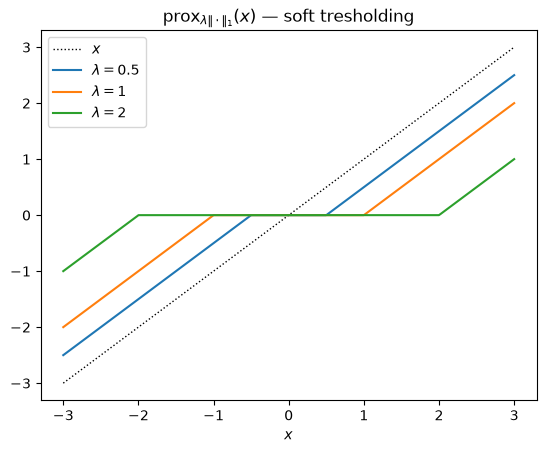

In [97]:
def soft_threshold(x, tau):
    return np.maximum(np.abs(x) - tau, 0.0) * np.sign(x)


print(soft_threshold(np.array([3.0, -0.5, -2.0, 1.0, 0.0]), 1.0))   # [2, 0, -1, 0, 0]

z = np.linspace(-3, 3, 600)
plt.plot(z, z, "k:", lw=1, label="$x$")
for tau in [0.5, 1, 2]:
    plt.plot(z, soft_threshold(z, tau), label=rf"$\lambda = {tau}$")
plt.xlabel("$x$")
plt.title(r"$\mathrm{prox}_{\lambda\|\cdot\|_1}(x)$ — soft tresholding")
plt.legend()
plt.show()

### Задача LASSO
$$F(w) = \underbrace{\frac{1}{2n}\|y - Xw\|_2^2}_{f(w)\ \text{— гладкая}} + \underbrace{\lambda\|w\|_1}_{r(w)\ \text{— негладкая}}, \qquad \nabla f(w) = \frac1n X^\top(Xw - y), \qquad L = \frac1n\lambda_{\max}(X^\top X).$$

In [98]:
def F(w, X, y, lam):
    r = y - X @ w
    return r @ r / (2 * len(y)) + lam * np.sum(np.abs(w))


def grad_f(w, X, y):
    return X.T @ (X @ w - y) / len(y)


def lipschitz(X):
    return np.linalg.eigvalsh(X.T @ X).max() / X.shape[0]


def r2(y, y_pred):
    return 1 - np.sum((y - y_pred) ** 2) / np.sum((y - y.mean()) ** 2)

In [99]:
def prepare(X_tr, X_te, y_tr, y_te):
    mean, std = X_tr.mean(axis=0), X_tr.std(axis=0)
    y_mean = y_tr.mean()
    return (X_tr - mean) / std, (X_te - mean) / std, y_tr - y_mean, y_te - y_mean, y_mean

In [100]:
class History:

    def __init__(self, X, y, lam):
        self.X, self.y, self.lam = X, y, lam
        self.F, self.zeros, self.time = [], [], []
        self.elapsed, self._t0 = 0.0, time.perf_counter()

    def add(self, w):
        self.elapsed += time.perf_counter() - self._t0       # время шагов метода
        self.F.append(F(w, self.X, self.y, self.lam))
        self.zeros.append(np.sum(w == 0))
        self.time.append(self.elapsed)
        self._t0 = time.perf_counter()

    def result(self):
        return {"F": np.array(self.F), "zeros": np.array(self.zeros), "time": np.array(self.time)}


class LassoModel:

    def __init__(self, lam=1.0, n_iter=1000):
        self.lam = lam
        self.n_iter = n_iter

    def fit(self, X, y):
        raise NotImplementedError

    def predict(self, X):
        return X @ self.coef_

    def score(self, X, y):
        return r2(y, self.predict(X))

##Методы
###Субградиентный метод
$$w^{k+1} = w^k - \gamma_k g^k, \qquad g^k = \nabla f(w^k) + \lambda\,\mathrm{sign}(w^k) \in \partial F(w^k), \qquad \gamma_k = \frac{R}{M\sqrt{k}}.$$

**Как берутся $M$ и $R$ для LASSO**:
* $M = \frac1n\|X^\top y\| + \lambda\sqrt d$ — норма субградиента в начальной точке $w^0 = 0$;
* $R = \|w_{\text{ridge}}\|$ — норма решения гребневой регрессии с тем же $\lambda$.

In [101]:
class LassoSubgradient(LassoModel):
    def fit(self, X, y):
        h = History(X, y, self.lam)
        n, d = X.shape
        K = self.n_iter
        M = np.linalg.norm(X.T @ y) / n + self.lam * np.sqrt(d)
        R = np.linalg.norm(np.linalg.solve(X.T @ X + n * self.lam * np.eye(d), X.T @ y))
        gamma = R / (M * np.sqrt(K))

        w = np.zeros(d)
        w_sum = np.zeros(d)
        h.add(w)
        for k in range(K):
            w_sum += w
            g = grad_f(w, X, y) + self.lam * np.sign(w)
            w = w - gamma * g
            h.add(w_sum / (k + 1))
        self.coef_, self.history_ = w_sum / K, h.result()
        return self

### ISTA (проксимальный градиентный метод)
Градиентный шаг по гладкой части, затем prox негладкой — мягкий порог с порогом $\gamma\lambda = \lambda/L$:
$$w^{k+1} = \mathrm{prox}_{\frac1L r}\Big(w^k - \tfrac1L\nabla f(w^k)\Big) = S_{\lambda/L}\Big(w^k - \tfrac1L\nabla f(w^k)\Big).$$
Оценка: $F(w^K) - F^* \le \dfrac{L\|w^0 - w^*\|^2}{2K}$

In [102]:
class LassoISTA(LassoModel):
    def fit(self, X, y):
        L = lipschitz(X)
        h = History(X, y, self.lam)

        w = np.zeros(X.shape[1])
        h.add(w)
        for k in range(self.n_iter):
            z = w - grad_f(w, X, y) / L #шаг градиента
            w = soft_threshold(z, self.lam / L)
            h.add(w)
        self.coef_, self.history_ = w, h.result()
        return self

### FISTA (ускоренный проксимальный градиентный метод)
Тот же шаг ISTA, но из точки $v^k$ с инерцией :
$$w^{k+1} = S_{\lambda/L}\Big(v^k - \tfrac1L\nabla f(v^k)\Big), \quad t_{k+1} = \frac{1 + \sqrt{1 + 4t_k^2}}{2}, \quad v^{k+1} = w^{k+1} + \frac{t_k - 1}{t_{k+1}}(w^{k+1} - w^k).$$
Оценка: $F(w^K) - F^* \le \dfrac{2L\|w^0 - w^*\|^2}{(K+1)^2}$.

In [103]:
class LassoFISTA(LassoModel):

    def fit(self, X, y):
        L = lipschitz(X)
        h = History(X, y, self.lam)

        w = np.zeros(X.shape[1])
        v, t = w.copy(), 1.0
        h.add(w)
        for k in range(self.n_iter):
            w_new = soft_threshold(v - grad_f(v, X, y) / L, self.lam / L)
            t_new = (1 + np.sqrt(1 + 4 * t ** 2)) / 2
            v = w_new + (t - 1) / t_new * (w_new - w)
            w, t = w_new, t_new
            h.add(w)
        self.coef_, self.history_ = w, h.result()
        return self

### 3.4. Циклический покоординатный спуск
Координаты обновляются по очереди $1, 2, \dots, d$; каждая — точный минимум $F$ по ней, т.е. мягкий порог по одной координате с **собственным** шагом $1/a_j$:
$$w_j \leftarrow S_{\lambda/a_j}\Big(w_j + \frac{\langle X_j, r\rangle}{n a_j}\Big), \qquad a_j = \frac{\|X_j\|^2}{n}, \qquad r = y - Xw.$$
В отличие от ISTA, при обновлении $w_j$ уже используются новые $w_1, \dots, w_{j-1}$. Одна **эпоха** — проход по всем координатам.

In [104]:
class LassoCD(LassoModel):
    def fit(self, X, y):
        h = History(X, y, self.lam)
        n, d = X.shape
        a = np.sum(X ** 2, axis=0) / n

        w = np.zeros(d)
        r = y - X @ w                                  # вектор остатков
        h.add(w)
        for k in range(self.n_iter):
            for j in range(d):
                w_old = w[j]
                w[j] = soft_threshold(w_old + X[:, j] @ r / (n * a[j]), self.lam / a[j])
                if w[j] != w_old:
                    r -= X[:, j] * (w[j] - w_old)      # пересчёт остатков
            h.add(w)
        self.coef_, self.history_ = w, h.result()
        return self

## Эталон и двойственный разрыв
Точный минимум $F^*$ неизвестен. Эталон $F_{\mathrm{ref}}$ считаем независимой реализацией (`sklearn.Lasso` минимизирует ту же функцию), а его точность проверяем **двойственным разрывом**: для $\theta = r / \max\{1, \|X^\top r\|_\infty / (n\lambda)\}$
$$D(\theta) = \frac1n\langle\theta, y\rangle - \frac1{2n}\|\theta\|^2 \le F^* \le F_{\mathrm{ref}}, \qquad\text{значит}\qquad 0 \le F_{\mathrm{ref}} - F^* \le F_{\mathrm{ref}} - D(\theta).$$

In [105]:
def reference(X, y, lam):
    n = len(y)
    w = Lasso(alpha=lam, fit_intercept=False, tol=1e-14, max_iter=1_000_000).fit(X, y).coef_
    r = y - X @ w
    theta = r / max(1.0, np.max(np.abs(X.T @ r)) / (n * lam))
    D = theta @ y / n - theta @ theta / (2 * n)
    F_ref = F(w, X, y, lam)
    return w, F_ref, F_ref - D

##Сравнение
Каждая модель обучается (`fit`) на одних и тех же данных. Одинаковые условия: одна задача, $w^0 = 0$, один эталон, одинаковое число итераций $K$ (у покоординатного спуска — эпох). Графики:
1. относительная невязка $(F(w^k) - F_{\mathrm{ref}})/F_{\mathrm{ref}}$ по итерациям + теоретические оценки ($R = \|w_{\mathrm{ref}}\|$);
2. то же по времени (итерации разной стоимости);
3. число **точных** нулей.

In [106]:
MODELS = {"субградиентный": LassoSubgradient, "ISTA": LassoISTA, "FISTA": LassoFISTA, "покоординатный спуск": LassoCD}


def compare(X, y, lam, K, title):
    """X, y — подготовленная обучающая выборка (функция prepare)."""
    w_ref, F_ref, gap = reference(X, y, lam)
    print(f"F_ref = {F_ref:.6f},  двойственный разрыв {gap:.1e},  ненулевых в эталоне {np.sum(w_ref != 0)} из {len(w_ref)}")
    models = {name: cls(lam=lam, n_iter=K).fit(X, y) for name, cls in MODELS.items()}

    fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
    for name, m in models.items():
        h = m.history_
        res = np.maximum((h["F"] - F_ref) / F_ref, 1e-16)
        axes[0].semilogy(res, label=name)
        axes[1].semilogy(h["time"], res, label=name)
        axes[2].plot(h["zeros"], label=name)
    # теоретические оценки (относительно F_ref)
    L, R2 = lipschitz(X), w_ref @ w_ref
    k = np.arange(1, K + 1)
    axes[0].semilogy(k, L * R2 / (2 * k) / F_ref, "k--", lw=1, label=r"ISTA: $LR^2/(2K)$")
    axes[0].semilogy(k, 2 * L * R2 / (k + 1) ** 2 / F_ref, "k:", lw=1.5, label=r"FISTA: $2LR^2/(K+1)^2$")
    axes[2].axhline(np.sum(w_ref == 0), color="k", ls="--", lw=1, label="в этафлоне")
    axes[0].set(xlabel="итерация (для покоорд. спуска — эпоха)", ylabel=r"$(F(w^k)-F_{ref})/F_{ref}$", ylim=(1e-16, 10))
    axes[1].set(xlabel="время, с (логарифмическая шкала)", xscale="log", ylim=(1e-16, 10))
    axes[2].set(xlabel="итерация", ylabel="число точных нулей")
    for ax in axes:
        ax.legend(fontsize=9)
    fig.suptitle(title)
    plt.show()

    rows = []
    for name, m in models.items():
        h, w = m.history_, m.coef_
        res = (h["F"] - F_ref) / F_ref
        first = lambda eps: next((i for i, v in enumerate(res) if v <= eps), "—")
        rows.append({"метод": name, "невязка в конце": f"{max(res[-1], 0):.1e}",
                     "итераций до 1e-2": first(1e-2), "до 1e-4": first(1e-4), "до 1e-8": first(1e-8),
                     "время, с": round(h["time"][-1], 3), "точных нулей": int(np.sum(w == 0))})
    print(pd.DataFrame(rows).to_string(index=False))
    return models

### 5.1. Модельные данные
Истинное решение разреженное: значимы только 5 признаков из 100. Данные делятся на обучающую и тестовую части (`train_test_split`), методы сравниваются на обучающей.

F_ref = 2.964312,  двойственный разрыв 1.0e-13,  ненулевых в эталоне 32 из 100


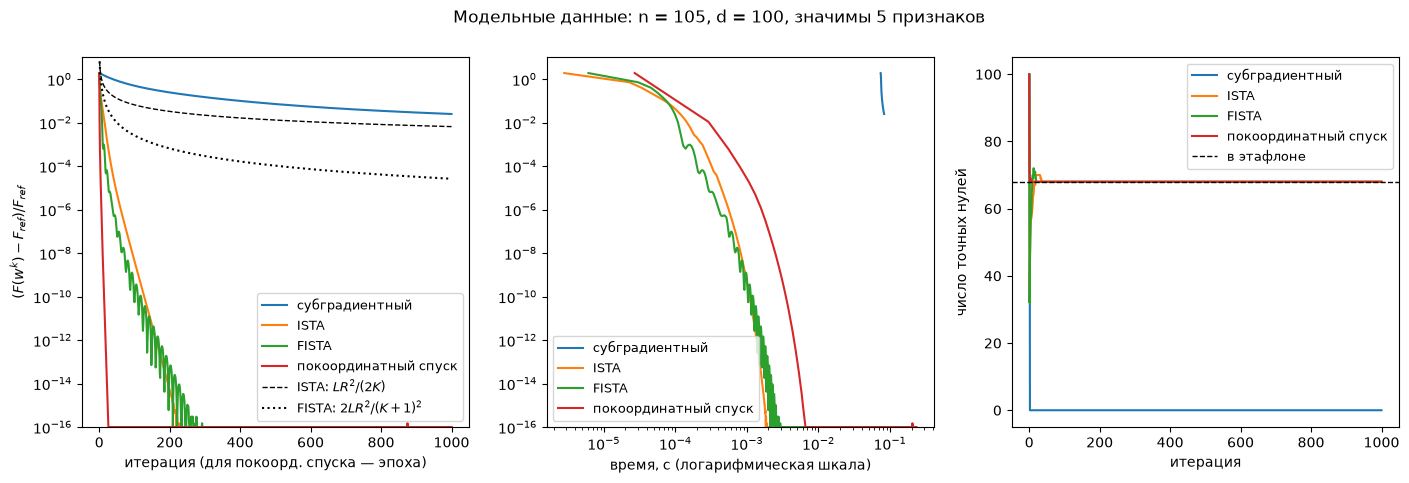

               метод невязка в конце итераций до 1e-2 до 1e-4 до 1e-8  время, с  точных нулей
      субградиентный         2.5e-02                —       —       —     0.083             0
                ISTA         0.0e+00               16      35      94     0.008            68
               FISTA         0.0e+00                9      18      72     0.010            68
покоординатный спуск         0.0e+00                2       3      10     0.234            68


In [107]:
rng = np.random.default_rng(SEED)
n, d = 150, 100
X = rng.standard_normal((n, d))
w_true = np.zeros(d)
w_true[:5] = [3, -2, 1.5, 1, -1]
y = X @ w_true + 2 * rng.standard_normal(n)
X_tr_s, X_te_s, y_tr_s, y_te_s = train_test_split(X, y, test_size=0.3, random_state=0)
X_tr_s, X_te_s, y_tr_s, y_te_s, _ = prepare(X_tr_s, X_te_s, y_tr_s, y_te_s)

models_syn = compare(X_tr_s, y_tr_s, lam=0.2, K=1000, title=f"Модельные данные: n = {X_tr_s.shape[0]}, d = {X_tr_s.shape[1]}, значимы 5 признаков")

F_ref = 1728.750895,  двойственный разрыв 7.0e-12,  ненулевых в эталоне 18 из 285


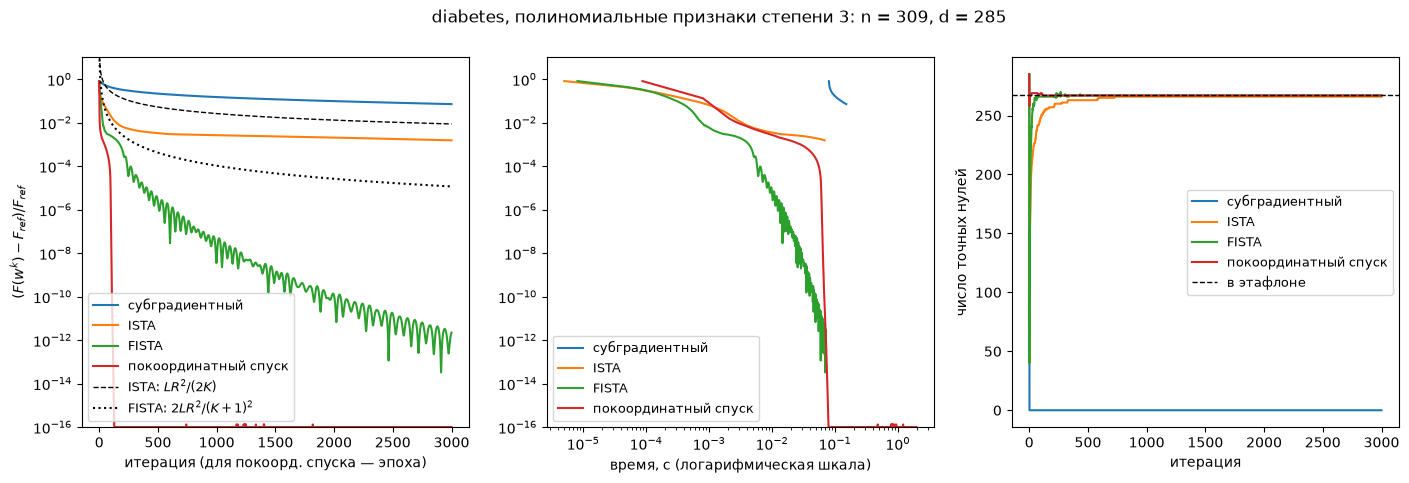

               метод невязка в конце итераций до 1e-2 до 1e-4 до 1e-8  время, с  точных нулей
      субградиентный         7.1e-02                —       —       —     0.151             0
                ISTA         1.5e-03              146       —       —     0.068           266
               FISTA         2.2e-12               30     239     993     0.072           267
покоординатный спуск         0.0e+00                5      89     104     1.968           267


In [108]:
data = load_diabetes()
X_poly = PolynomialFeatures(3, include_bias=False).fit_transform(data.data)
X_tr, X_te, y_tr, y_te = train_test_split(X_poly, data.target, test_size=0.3, random_state=0)
X_tr, X_te, y_tr, y_te, y_mean = prepare(X_tr, X_te, y_tr, y_te)

models_diab = compare(X_tr, y_tr, lam=4.64, K=3000, title=f"diabetes, полиномиальные признаки степени 3: n = {X_tr.shape[0]}, d = {X_tr.shape[1]}")

In [109]:

rows = [{"модель": name, "R2 train": round(m.score(X_tr, y_tr), 3), "R2 test": round(m.score(X_te, y_te), 3),
         "ненулевых": int(np.sum(m.coef_ != 0))} for name, m in models_diab.items()]
print(pd.DataFrame(rows).to_string(index=False))
print("первые 5 предсказаний ISTA (исходная шкала):", np.round(models_diab["ISTA"].predict(X_te[:5]) + y_mean, 1))

              модель  R2 train  R2 test  ненулевых
      субградиентный     0.530    0.382        285
                ISTA     0.577    0.370         19
               FISTA     0.578    0.368         18
покоординатный спуск     0.578    0.368         18
первые 5 предсказаний ISTA (исходная шкала): [245.  226.8 159.9 120.5 168. ]
